# 02 · Limpieza, EDA y Feature Engineering

**Entrada** (`data/raw/`): dataset histórico de Kaggle + `upcoming_enriched.json` (generado en el 01).
**Salida** (`data/processed/`):
- `games_processed.csv` → juegos históricos con features + target (para entrenar).
- `upcoming_processed.csv` → próximos lanzamientos con **las mismas features** (para predecir).
- `feature_list.json` → lista de features que usará el modelo.

Regla de oro: **solo usamos como features información disponible ANTES del lanzamiento**.

In [1]:
import ast
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

RAW = Path("../data/raw")
PROC = Path("../data/processed")
PROC.mkdir(parents=True, exist_ok=True)

## 0. Parámetros

Todas las decisiones importantes están aquí arriba para poder cambiarlas fácilmente.

In [2]:
HIST_PATH = RAW / "steam_games_lite.csv.gz"             
UP_PATH = RAW / "upcoming_enriched.json"

# Ventana de entrenamiento: juegos con al menos 12 meses a la venta
FECHA_INICIO = pd.Timestamp("2015-01-01")
FECHA_CORTE = pd.Timestamp("2025-11-25")     # fecha de descarga del dataset - 12 meses

# Definición de éxito
MIN_RESENAS = 500        # nº mínimo de reseñas (popularidad)
MIN_POSITIVAS = 0.80     # % mínimo de reseñas positivas (calidad) -> "Muy positivas" en Steam

# Tamaño del vocabulario para el one-hot de listas
TOP_GENRES = 20
TOP_CATS = 25
TOP_TAGS = 40
N_TAGS_JUEGO = 5         # la API de próximos solo da ~4-5 tags por juego -> igualamos

# Categorías que se añaden DESPUÉS del lanzamiento (leakage)
CATS_EXCLUIR = {"Steam Trading Cards"}

## 1. Carga

In [3]:
hist_raw = pd.read_csv(HIST_PATH, low_memory=False).rename(columns={"app_id": "appid"})
up_raw = pd.read_json(UP_PATH)
print("Histórico:", hist_raw.shape, "| Próximos:", up_raw.shape)

Histórico: (150863, 21) | Próximos: (36, 27)


## 2. Funciones de parseo

Los formatos difieren entre fuentes:

| Columna | Histórico | Próximos |
|---|---|---|
| genres / categories | texto JSON `[{"id": .., "description": "Indie"}]` | lista `['Indie']` |
| developers / publishers | texto JSON `["DevSanja"]` | lista |
| tags | texto (lista o dict con votos) | lista |
| supported_languages | `English, German` | `English, German...` (puede traer HTML) |
| screenshots / movies | texto JSON con lista de dicts | ya contados (`n_screenshots`, `n_movies`) |

In [4]:
def parse_list(x):
    """Convierte texto JSON / repr de Python / 'a, b, c' en lista o dict."""
    if isinstance(x, (list, dict)):
        return x
    if x is None or pd.isna(x):
        return []
    s = str(x).strip()
    if not s:
        return []
    for loader in (json.loads, ast.literal_eval):
        try:
            return loader(s)
        except Exception:
            pass
    return [t.strip() for t in s.split(",") if t.strip()]


def to_names(x, top=None):
    """Devuelve una lista de nombres. Si es dict de votos (tags), ordena por votos."""
    v = parse_list(x)
    if isinstance(v, dict):
        v = [k for k, _ in sorted(v.items(),
                                  key=lambda kv: -kv[1] if isinstance(kv[1], (int, float)) else 0)]
    names = []
    for e in v if isinstance(v, list) else []:
        n = (e.get("description") or e.get("name")) if isinstance(e, dict) else e
        if n:
            names.append(str(n).strip())
    return names[:top] if top else names


def parse_languages(x):
    """Lista de idiomas limpia (quita HTML y la nota de 'full audio support')."""
    if isinstance(x, list):
        return [str(i).strip() for i in x if str(i).strip()]
    if x is None or pd.isna(x):
        return []
    s = re.sub(r"<[^>]+>", "", str(x))
    s = s.split("languages with full audio support")[0].replace("*", "")
    v = parse_list(s)
    return [str(i).strip() for i in v if str(i).strip()] if isinstance(v, list) else []


def count_items(x):
    v = parse_list(x)
    return len(v) if isinstance(v, (list, dict)) else 0


def text_len(x):
    if x is None or (not isinstance(x, str) and pd.isna(x)):
        return 0
    return len(re.sub(r"<[^>]+>", " ", str(x)).split())   # nº de palabras sin HTML


def to_bool_int(s):
    return s.astype(str).str.strip().str.lower().isin(["true", "1", "yes"]).astype(int)


# Comprobación rápida con los ejemplos reales
print(to_names('[{"id": "4", "description": "Casual"}, {"id": "23", "description": "Indie"}]'))
print(to_names('["DevSanja"]'))
print(to_names("{'Indie': 120, 'Action': 300}"))
print(parse_languages("English, German, Russian"))
print(parse_languages("English<strong>*</strong>, Spanish - Spain<br><strong>*</strong>languages with full audio support"))

['Casual', 'Indie']
['DevSanja']
['Action', 'Indie']
['English', 'German', 'Russian']
['English', 'Spanish - Spain']


## 3. Limpieza del histórico

In [5]:
hist = hist_raw.copy()
n0 = len(hist)

hist = hist.drop_duplicates("appid")
hist = hist[hist["price_status"] != "unavailable"]           # retirados de la tienda
hist["release_date"] = pd.to_datetime(hist["release_date"], errors="coerce", format="mixed")
hist = hist.dropna(subset=["release_date", "name"])

for c in ["positive", "negative"]:
    hist[c] = pd.to_numeric(hist[c], errors="coerce").fillna(0)

print(f"{n0:,} -> {len(hist):,} filas tras limpieza básica")

150,863 -> 149,401 filas tras limpieza básica


In [6]:
def formato_tags(x):
    v = parse_list(x)
    if isinstance(v, dict):
        return "diccionario" if v else "vacío"
    return "lista" if v else "vacío"

fmt = hist["tags"].map(formato_tags)
(pd.crosstab(hist["release_date"].dt.year, fmt, normalize="index") * 100).round(1).loc[2015:2026]

tags,diccionario,lista,vacío
release_date,,,
2015,99.8,0.0,0.2
2016,99.8,0.0,0.2
2017,98.7,0.0,1.3
2018,96.7,0.0,3.3
2019,92.5,0.1,7.5
2020,40.0,51.2,8.8
2021,10.4,66.9,22.7
2022,5.3,65.6,29.1
2023,3.2,63.8,33.0


## 4. Definición del target: ¿qué es un juego exitoso?

`exitoso = 1` si el juego tiene **≥ MIN_RESENAS reseñas** (popularidad) **y ≥ MIN_POSITIVAS % positivas** (calidad).

El nº de reseñas es un buen proxy de ventas (regla de Boxleiter: ~30-60 ventas por reseña), así que 500 reseñas ≈ 15.000-30.000 copias.

In [7]:
hist["n_reviews"] = hist["positive"] + hist["negative"]
hist["pct_positive"] = np.where(hist["n_reviews"] > 0, hist["positive"] / hist["n_reviews"], np.nan)
hist["exitoso"] = ((hist["n_reviews"] >= MIN_RESENAS) &
                   (hist["pct_positive"] >= MIN_POSITIVAS)).astype(int)

# ¿Cómo cambia el % de éxitos con otros umbrales? (sobre la ventana de entrenamiento)
ventana = hist[(hist["release_date"] >= FECHA_INICIO) & (hist["release_date"] <= FECHA_CORTE)]
tabla = pd.DataFrame({
    f"≥{int(p*100)}% pos": [((ventana["n_reviews"] >= r) & (ventana["pct_positive"] >= p)).mean() * 100
                            for r in [100, 250, 500, 1000, 5000]]
    for p in [0.70, 0.80, 0.90]
}, index=[f"≥{r} reseñas" for r in [100, 250, 500, 1000, 5000]]).round(2)
print("% de juegos exitosos según umbral:")
tabla

% de juegos exitosos según umbral:


,≥70% pos,≥80% pos,≥90% pos
≥100 reseñas,13.42,9.99,4.96
≥250 reseñas,8.93,6.82,3.43
≥500 reseñas,6.32,4.90,2.54
≥1000 reseñas,4.34,3.45,1.88
≥5000 reseñas,1.63,1.37,0.80


## 5. Feature engineering

Construimos **exactamente las mismas features** en las dos fuentes con una única función.

In [8]:
def build_base(df, fuente):
    """Features 'planas' + columnas auxiliares de listas (_l) para el one-hot posterior."""
    h = fuente == "hist"
    out = pd.DataFrame(index=df.index)
    out["appid"] = df["appid"].astype("int64")
    out["name"] = df["name"]

    if h:
        out["release_date"] = df["release_date"]
        out["is_free"] = (df["price_status"] == "free").astype(int)
        out["n_screenshots"] = df["n_screenshots"] if "n_screenshots" in df else df["screenshots"].map(count_items)
        out["n_movies"] = df["n_movies"] if "n_movies" in df else df["movies"].map(count_items)
    else:
        def fecha_exacta(s):
            # Solo fechas con día ("Nov 24, 2026"); "Q1 2027" o "2027" -> NaT (mes desconocido)
            s = s.astype("string")
            return pd.to_datetime(s.where(s.str.contains(",", na=False)), errors="coerce", format="mixed")
        fecha = fecha_exacta(df["release_date_store"])
        if "release_date_api" in df:
            fecha = fecha.fillna(fecha_exacta(df["release_date_api"]))
        out["release_date"] = fecha
        out["is_free"] = to_bool_int(df["is_free"])
        out["n_screenshots"] = pd.to_numeric(df["n_screenshots"], errors="coerce").fillna(0)
        out["n_movies"] = pd.to_numeric(df["n_movies"], errors="coerce").fillna(0)

    out["price"] = pd.to_numeric(df["price"], errors="coerce")       # NaN = sin precio anunciado
    out.loc[out["is_free"] == 1, "price"] = 0.0
    for p in ["windows", "mac", "linux"]:
        out[p] = to_bool_int(df[p])
    out["n_platforms"] = out[["windows", "mac", "linux"]].sum(axis=1)

    out["achievements"] = pd.to_numeric(df["achievements"], errors="coerce").fillna(0)
    if not h:
        # Steam no publica los logros hasta cerca del lanzamiento: 0 = desconocido
        out["achievements"] = out["achievements"].replace(0, np.nan)
    langs = df["supported_languages"].map(parse_languages)
    out["n_languages"] = langs.map(len)
    out["has_spanish"] = langs.map(lambda l: int(any("Spanish" in x for x in l)))
    out["has_chinese"] = langs.map(lambda l: int(any("Chinese" in x for x in l)))

    out["len_short_desc"] = (df["len_short_desc"] if "len_short_desc" in df
        else df["short_description"].map(text_len))
    out["len_detailed_desc"] = (df["len_detailed_desc"] if "len_detailed_desc" in df
        else df["detailed_description"].map(text_len))

    out["release_month"] = out["release_date"].dt.month
    out["release_weekday"] = out["release_date"].dt.weekday

    out["genres_l"] = df["genres"].map(to_names)
    out["categories_l"] = df["categories"].map(lambda x: [c for c in to_names(x) if c not in CATS_EXCLUIR])
    out["tags_l"] = df["tags"].map(lambda x: to_names(x, top=N_TAGS_JUEGO))
    out["developers_l"] = df["developers"].map(to_names)
    out["publishers_l"] = df["publishers"].map(to_names)

    out["n_genres"] = out["genres_l"].map(len)
    out["n_categories"] = out["categories_l"].map(len)
    out["self_published"] = [int(bool(set(d) & set(p))) for d, p in zip(out["developers_l"], out["publishers_l"])]
    out["dev0"] = out["developers_l"].map(lambda l: l[0] if l else "UNKNOWN")
    out["pub0"] = out["publishers_l"].map(lambda l: l[0] if l else "UNKNOWN")
    return out


hist_f = build_base(hist, "hist")
hist_f["exitoso"] = hist["exitoso"]
hist_f["n_reviews"] = hist["n_reviews"]
up_f = build_base(up_raw, "up")
print(hist_f.shape, up_f.shape)

(149401, 31) (36, 29)


### 5.1 Experiencia del desarrollador / publisher

Para cada juego contamos **cuántos juegos había publicado antes** su desarrollador (y cuántos fueron éxitos), usando **solo juegos anteriores en el tiempo**. Para los próximos lanzamientos, todo el histórico es "anterior".

> Pequeña fuga a tener en cuenta en la memoria: el éxito de los juegos previos se mide con las reseñas de hoy, no con las que tenían en la fecha del lanzamiento.

In [9]:
hist_f = hist_f.sort_values("release_date")

g = hist_f.groupby("dev0")
hist_f["dev_prev_games"] = g.cumcount()
hist_f["dev_prev_hits"] = g["exitoso"].cumsum() - hist_f["exitoso"]
hist_f["pub_prev_games"] = hist_f.groupby("pub0").cumcount()

dev_tot = hist_f.groupby("dev0").agg(games=("appid", "size"), hits=("exitoso", "sum"))
pub_tot = hist_f.groupby("pub0").size()
up_f["dev_prev_games"] = up_f["dev0"].map(dev_tot["games"]).fillna(0).astype(int)
up_f["dev_prev_hits"] = up_f["dev0"].map(dev_tot["hits"]).fillna(0).astype(int)
up_f["pub_prev_games"] = up_f["pub0"].map(pub_tot).fillna(0).astype(int)

# 'UNKNOWN' no es un desarrollador real
for df_ in (hist_f, up_f):
    df_.loc[df_["dev0"] == "UNKNOWN", ["dev_prev_games", "dev_prev_hits"]] = 0
    df_.loc[df_["pub0"] == "UNKNOWN", "pub_prev_games"] = 0

hist_f[["dev_prev_games", "dev_prev_hits", "pub_prev_games"]].describe().T

,count,mean,std,min,25%,50%,75%,max
dev_prev_games,149401.0,3.284228,12.748404,0.0,0.0,0.0,1.0,236.0
dev_prev_hits,149401.0,0.177442,1.262448,0.0,0.0,0.0,0.0,37.0
pub_prev_games,149401.0,7.797732,27.974112,0.0,0.0,0.0,2.0,535.0


### 5.2 Ventana de entrenamiento

- Juegos lanzados entre `FECHA_INICIO` y `FECHA_CORTE` (≥ 12 meses a la venta).
- Solo juegos **con al menos un tag**: todos los próximos lanzamientos tienen tags; en el histórico los juegos sin tags son casi siempre juegos sin jugadores (los tags los votan los usuarios), lo que sería una fuga.

In [10]:
mask = (hist_f["release_date"].between(FECHA_INICIO, FECHA_CORTE)) & (hist_f["tags_l"].map(len) > 0)
print("Éxito en juegos SIN tags (por eso los quitamos):",
      round(hist_f.loc[hist_f["tags_l"].map(len) == 0, "exitoso"].mean() * 100, 2), "%")
train_df = hist_f[mask].copy()
print(f"Juegos para entrenar: {len(train_df):,}")
print(f"% exitosos: {train_df['exitoso'].mean() * 100:.2f} %")

Éxito en juegos SIN tags (por eso los quitamos): 0.0 %
Juegos para entrenar: 78,593
% exitosos: 7.16 %


### 5.3 One-hot de géneros, categorías y tags

El vocabulario (top-N más frecuentes) se calcula **solo con los juegos de entrenamiento** y se aplica igual a los próximos.

In [11]:
def slug(s):
    return re.sub(r"[^0-9a-z]+", "_", s.lower()).strip("_")


def top_vocab(series, n):
    return series.explode().dropna().value_counts().head(n).index.tolist()


VOCAB = {
    "genre": top_vocab(train_df["genres_l"], TOP_GENRES),
    "cat": top_vocab(train_df["categories_l"], TOP_CATS),
    "tag": top_vocab(train_df["tags_l"], TOP_TAGS),
}
SRC = {"genre": "genres_l", "cat": "categories_l", "tag": "tags_l"}


def one_hot(df):
    cols = {}
    for pref, vocab in VOCAB.items():
        sets = df[SRC[pref]].map(set)
        for v in vocab:
            cols[f"{pref}_{slug(v)}"] = sets.map(lambda s, v=v: int(v in s))
    return pd.concat([df, pd.DataFrame(cols, index=df.index)], axis=1)


train_df = one_hot(train_df)
up_f = one_hot(up_f)

# Cobertura: ¿cuántos géneros/tags de los próximos caen dentro del vocabulario?
for pref in VOCAB:
    cov = up_f[SRC[pref]].map(lambda l, p=pref: any(x in VOCAB[p] for x in l)).mean()
    print(f"{pref}: {cov * 100:.0f}% de próximos tiene al menos uno en el vocabulario")

genre: 97% de próximos tiene al menos uno en el vocabulario
cat: 100% de próximos tiene al menos uno en el vocabulario
tag: 86% de próximos tiene al menos uno en el vocabulario


## 6. EDA

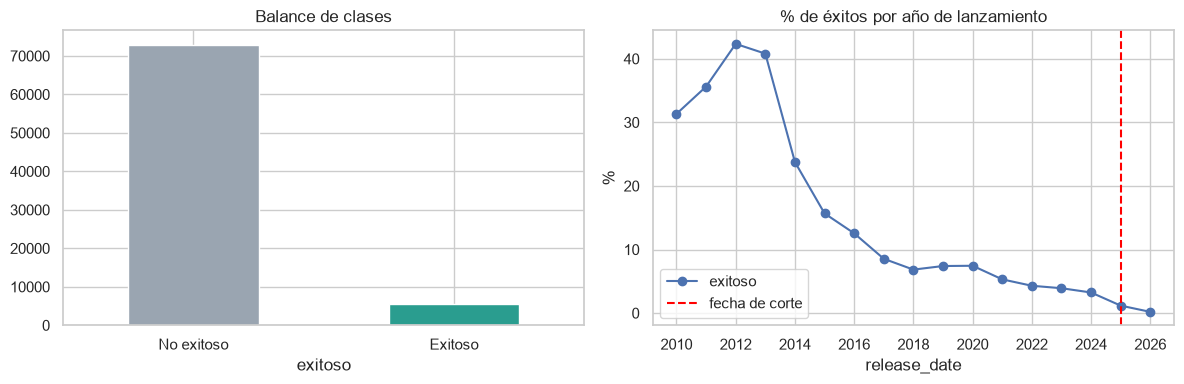

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
train_df["exitoso"].value_counts().plot.bar(ax=ax[0], color=["#9aa5b1", "#2a9d8f"])
ax[0].set_title("Balance de clases"); ax[0].set_xticklabels(["No exitoso", "Exitoso"], rotation=0)

por_anio = hist_f.groupby(hist_f["release_date"].dt.year)["exitoso"].mean() * 100
por_anio.loc[2010:].plot(ax=ax[1], marker="o")
ax[1].axvline(FECHA_CORTE.year, color="red", ls="--", label="fecha de corte")
ax[1].set_title("% de éxitos por año de lanzamiento"); ax[1].set_ylabel("%"); ax[1].legend()
plt.tight_layout(); plt.show()

*El % de éxito cae en los años recientes porque esos juegos aún no han acumulado reseñas → justifica la fecha de corte.*

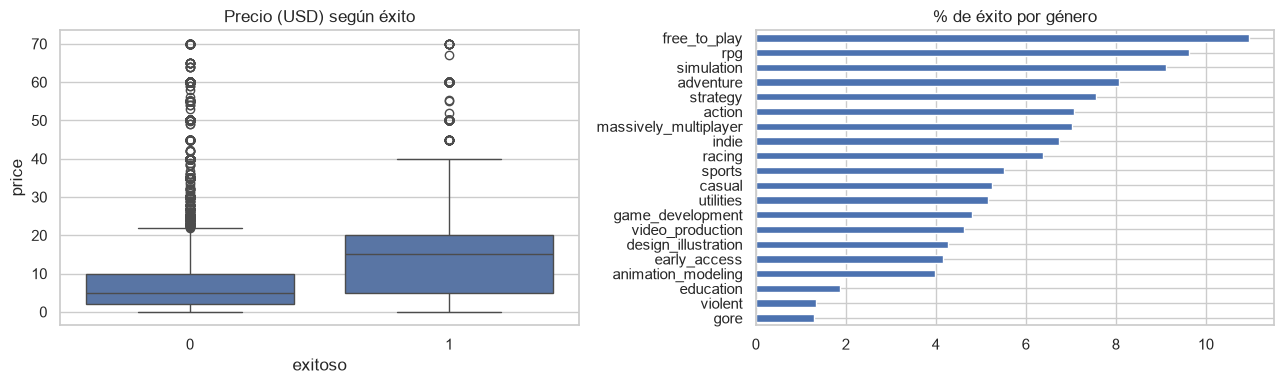

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=train_df[train_df["price"] <= 70], x="exitoso", y="price", ax=ax[0])
ax[0].set_title("Precio (USD) según éxito")

gcols = [c for c in train_df if c.startswith("genre_")]
tasa = pd.Series({c.replace("genre_", ""): train_df.loc[train_df[c] == 1, "exitoso"].mean() * 100
                  for c in gcols}).sort_values()
tasa.plot.barh(ax=ax[1]); ax[1].set_title("% de éxito por género")
plt.tight_layout(); plt.show()

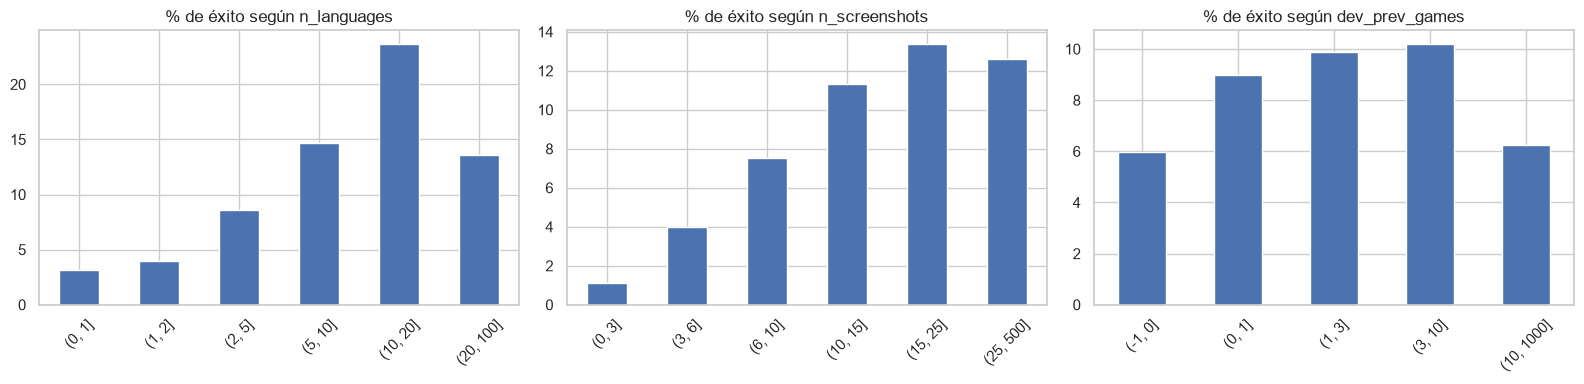

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col, bins in zip(ax,
                        ["n_languages", "n_screenshots", "dev_prev_games"],
                        [[0, 1, 2, 5, 10, 20, 100], [0, 3, 6, 10, 15, 25, 500], [-1, 0, 1, 3, 10, 1000]]):
    t = train_df.groupby(pd.cut(train_df[col], bins), observed=True)["exitoso"].mean() * 100
    t.plot.bar(ax=a); a.set_title(f"% de éxito según {col}"); a.set_xlabel(""); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

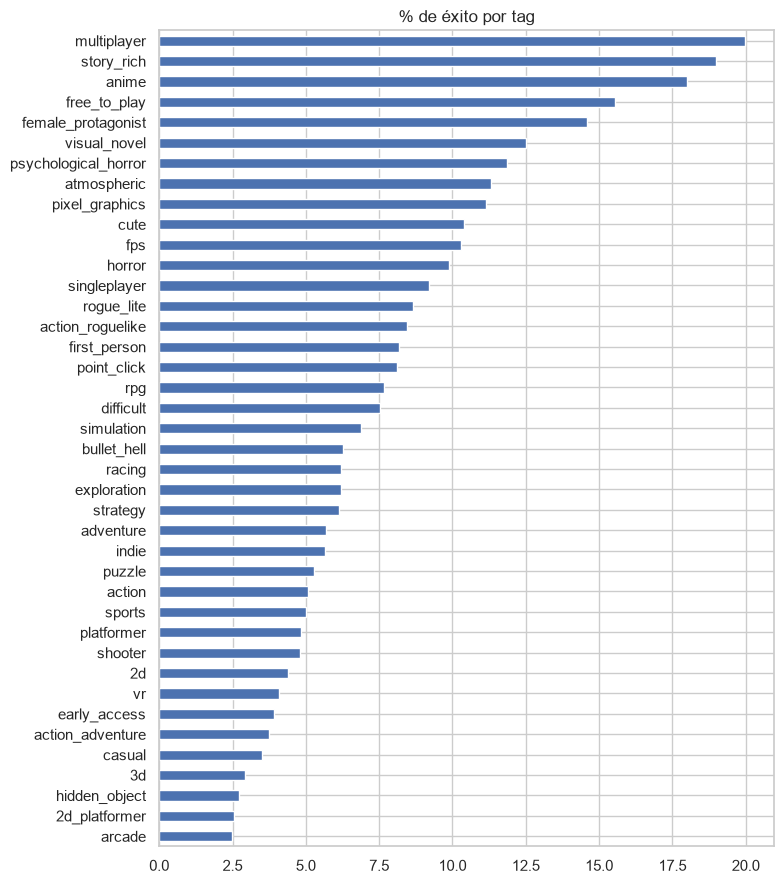

In [15]:
tcols = [c for c in train_df if c.startswith("tag_")]
tasa_tag = pd.Series({c.replace("tag_", ""): train_df.loc[train_df[c] == 1, "exitoso"].mean() * 100
                      for c in tcols}).sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
tasa_tag.plot.barh(ax=ax); ax.set_title("% de éxito por tag"); plt.tight_layout(); plt.show()

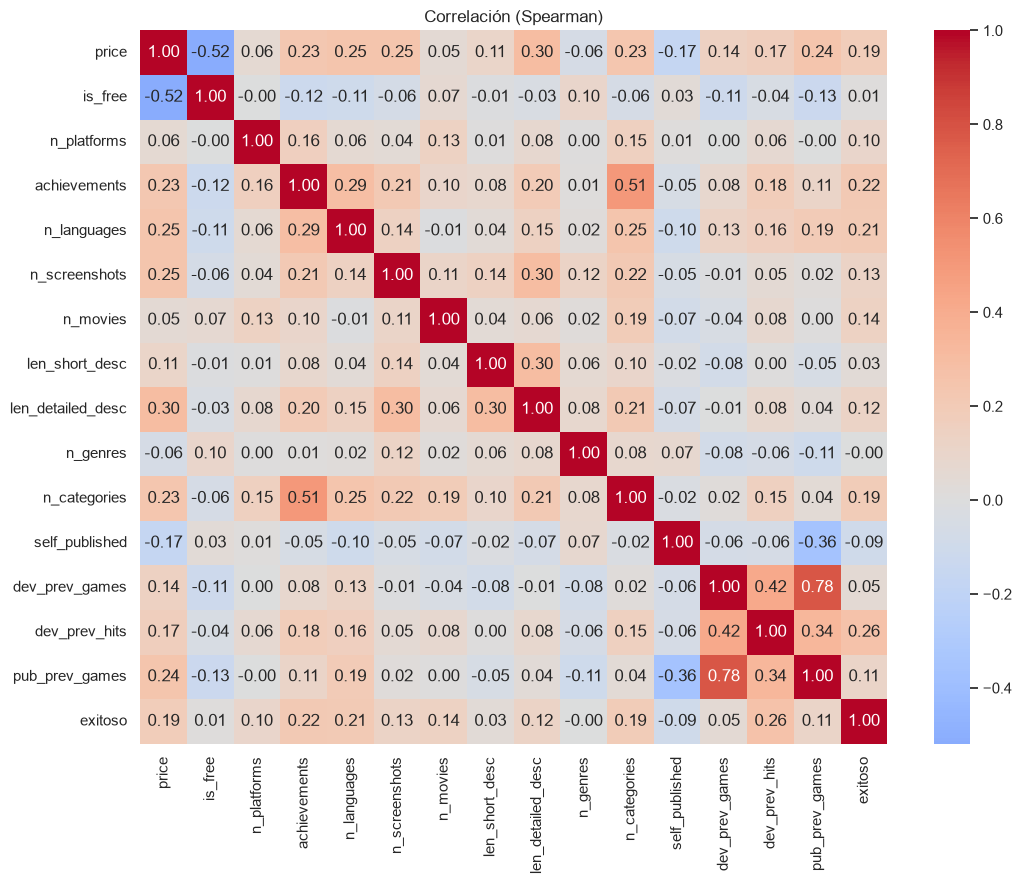

In [16]:
NUM = ["price", "is_free", "n_platforms", "achievements", "n_languages", "n_screenshots", "n_movies",
       "len_short_desc", "len_detailed_desc", "n_genres", "n_categories", "self_published",
       "dev_prev_games", "dev_prev_hits", "pub_prev_games", "exitoso"]
plt.figure(figsize=(11, 9))
sns.heatmap(train_df[NUM].corr(method="spearman"), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlación (Spearman)"); plt.tight_layout(); plt.show()

### 6.1 ¿Se parecen los próximos lanzamientos a los datos de entrenamiento?

Si las distribuciones difieren mucho (*data drift*), las predicciones serán menos fiables.

In [17]:
comp = ["price", "n_languages", "n_screenshots", "n_movies", "achievements", "len_detailed_desc", "dev_prev_games"]
pd.DataFrame({"train (mediana)": train_df[comp].median(), "próximos (mediana)": up_f[comp].median(),
              "próximos % nulos": up_f[comp].isna().mean() * 100}).round(1)

,train (mediana),próximos (mediana),próximos % nulos
price,5.0,10.0,75.0
n_languages,1.0,9.0,0.0
n_screenshots,7.0,10.0,0.0
n_movies,0.0,1.0,0.0
achievements,7.0,55.0,80.6
len_detailed_desc,181.0,287.0,0.0
dev_prev_games,0.0,0.0,0.0


## 7. Guardado

In [18]:
OHE = [c for c in train_df if c.startswith(("genre_", "cat_", "tag_"))]
FEATURES = [
    "price", "is_free", "windows", "mac", "linux", "n_platforms",
    "achievements", "n_languages", "has_spanish", "has_chinese",
    "n_screenshots", "n_movies", "len_short_desc", "len_detailed_desc",
    "release_month", "release_weekday", "n_genres", "n_categories", "self_published",
    "dev_prev_games", "dev_prev_hits", "pub_prev_games",
] + OHE
META = ["appid", "name", "release_date"]

train_df[META + FEATURES + ["exitoso", "n_reviews"]].to_csv(PROC / "games_processed.csv", index=False)
up_f[META + FEATURES].to_csv(PROC / "upcoming_processed.csv", index=False)
with open(PROC / "feature_list.json", "w", encoding="utf-8") as f:
    json.dump({"features": FEATURES, "target": "exitoso", "vocab": VOCAB,
               "params": {"MIN_RESENAS": MIN_RESENAS, "MIN_POSITIVAS": MIN_POSITIVAS,
                          "FECHA_INICIO": str(FECHA_INICIO.date()), "FECHA_CORTE": str(FECHA_CORTE.date())}},
              f, ensure_ascii=False, indent=2)

print(f"{len(FEATURES)} features | train: {len(train_df):,} | próximos: {len(up_f)}")

107 features | train: 78,593 | próximos: 36


## 8. Conclusiones

- Definición de éxito elegida y % de juegos exitosos: exitoso = >= 500 reseñas y >= 80 % positivas (~15-30k copias según la regla de Boxleiter, y etiqueta 'Muy positivas' de Steam). 7,16 % de positivos -> problema desbalanceado: no usaremos accuracy, compensaremos clases y evaluaremos con PR-AUC.
- Hallazgos del EDA: 
    - Nº de idiomas: del 3 % de éxito (1 idioma) al 23 % (11-20 idiomas).
    - Fichas cuidadas: del 1 % (0-3 capturas) al 13 % (16-25 capturas).
    - Precio: mediana ~15 $ en exitosos vs ~5 $ en no exitosos.
    - Tags con más éxito: Multiplayer, Story Rich, Anime (18-20 %); con menos: Arcade, 2D Platformer, Hidden Object (~2,5 %).
    - Experiencia del estudio: relación en U invertida (6 % debutantes, ~10 % con 1-10 juegos, 6 % con más de 10).
    - Ninguna variable tiene correlación > 0,26 con el éxito: el modelo debe combinarlas.
- Decisiones de limpieza: eliminados `unavailable`, juegos sin tags, juegos con < 12 meses a la venta.
- Riesgos: desbalance de clases, *drift* entre histórico y próximos, fuga leve en `dev_prev_hits`.